In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Welcome to Student Performance Analysis")
print("All libraries imported successfully")

Welcome to Student Performance Analysis
All libraries imported successfully


In [9]:
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

import zipfile
import io
import requests

response = requests.get(url)
outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

# Open the nested 'student.zip' inside the main zip file
with outer_zip.open("student.zip") as nested_zip_file:
    with zipfile.ZipFile(io.BytesIO(nested_zip_file.read())) as inner_zip:
        with inner_zip.open("student-mat.csv") as file:
            df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:
print("Rows and Columns:", df.shape)
print("Total Students:", len(df))
print("Total Features:", len(df.columns))

Rows and Columns: (395, 33)
Total Students: 395
Total Features: 33


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [13]:
print(df.isnull().sum)

<bound method DataFrame.sum of      school    sex    age  address  famsize  Pstatus   Medu   Fedu   Mjob  \
0     False  False  False    False    False    False  False  False  False   
1     False  False  False    False    False    False  False  False  False   
2     False  False  False    False    False    False  False  False  False   
3     False  False  False    False    False    False  False  False  False   
4     False  False  False    False    False    False  False  False  False   
..      ...    ...    ...      ...      ...      ...    ...    ...    ...   
390   False  False  False    False    False    False  False  False  False   
391   False  False  False    False    False    False  False  False  False   
392   False  False  False    False    False    False  False  False  False   
393   False  False  False    False    False    False  False  False  False   
394   False  False  False    False    False    False  False  False  False   

      Fjob  ...  famrel  freetime  goout   D

In [14]:
df["Average"] = (df["G1"] + df["G2"] + df["G3"]) / 3

df[["G1", "G2", "G3", "Average"]].head(10)

,G1,G2,G3,Average
0,5,6,6,5.666667
1,5,5,6,5.333333
2,7,8,10,8.333333
3,15,14,15,14.666667
4,6,10,10,8.666667
5,15,15,15,15.000000
6,12,12,11,11.666667
7,6,5,6,5.666667
8,16,18,19,17.666667
9,14,15,15,14.666667


In [15]:
print("Highest Average:", df["Average"].max())
print("Lowest Average:", df["Average"].min())
print("Class Average:", df["Average"].mean())

Highest Average: 19.333333333333332
Lowest Average: 1.3333333333333333
Class Average: 10.67932489451477


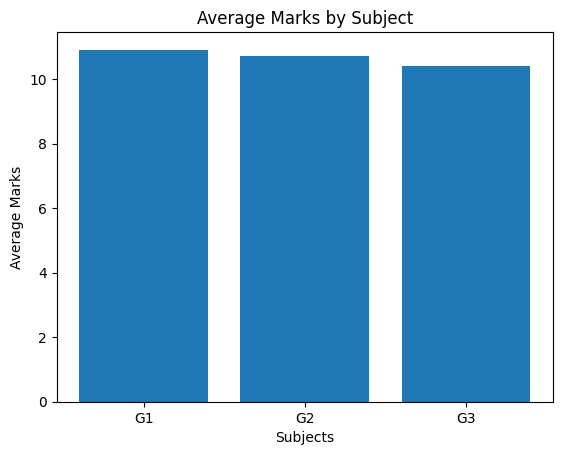

In [16]:
subjects = ["G1", "G2", "G3"]

averages = [
    df["G1"].mean(),
    df["G2"].mean(),
    df["G3"].mean()
]

plt.bar(subjects, averages)
plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.show()

In [18]:
df["Result"] = np.where(df["G3"] >= 10, "Pass", "Fail")

result_count = df["Result"].value_counts()

print(result_count)

Result
Pass    265
Fail    130
Name: count, dtype: int64


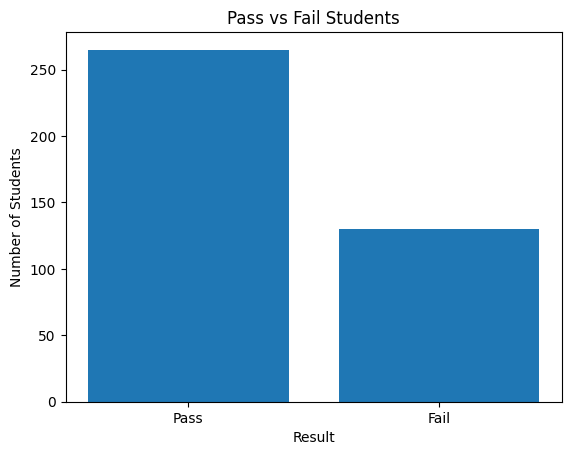

In [19]:
plt.bar(result_count.index, result_count.values)

plt.title("Pass vs Fail Students")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.show()

In [20]:
top_students = df.sort_values(
    by="G3", ascending=False
).head(10)

top_students[["school", "sex", "age", "G1", "G2", "G3", "Average"]]

,school,sex,age,G1,G2,G3,Average
47,GP,M,16,19,19,20,19.333333
286,GP,F,18,18,18,19,18.333333
374,MS,F,18,19,18,19,18.666667
110,GP,M,15,18,19,19,18.666667
8,GP,M,15,16,18,19,17.666667
113,GP,M,15,18,19,19,18.666667
91,GP,F,15,16,17,18,17.000000
42,GP,M,15,19,18,18,18.333333
36,GP,M,15,15,16,18,16.333333
104,GP,M,15,16,18,18,17.333333


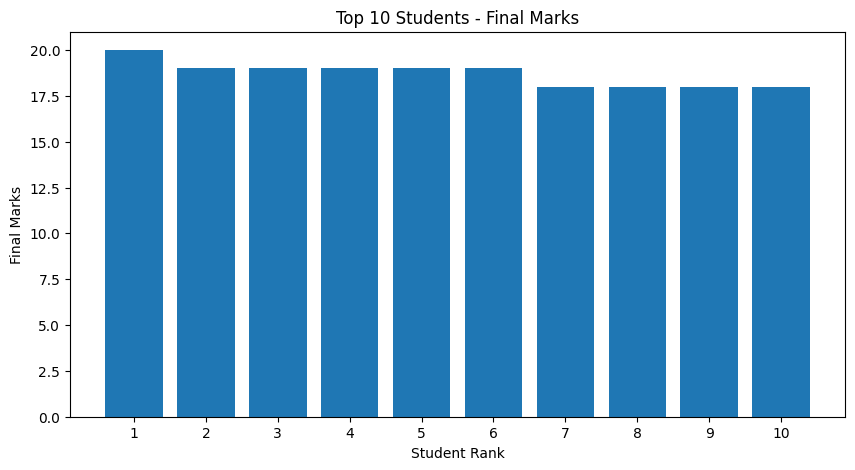

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(range(1, 11), top_students["G3"])

plt.title("Top 10 Students - Final Marks")
plt.xlabel("Student Rank")
plt.ylabel("Final Marks")

plt.xticks(range(1, 11))
plt.show()

In [22]:
print("STUDENT PERFORMANCE ANALYSIS")
print("--------------------------------")

print("Total Students:", len(df))
print("Class Average:", round(df["Average"].mean(), 2))
print("Highest Average:", round(df["Average"].max(), 2))
print("Lowest Average:", round(df["Average"].min(), 2))

print("\nPass Students:", (df["Result"] == "Pass").sum())
print("Fail Students:", (df["Result"] == "Fail").sum())

print("\nProject Completed Successfully!")

STUDENT PERFORMANCE ANALYSIS
--------------------------------
Total Students: 395
Class Average: 10.68
Highest Average: 19.33
Lowest Average: 1.33

Pass Students: 265
Fail Students: 130

Project Completed Successfully!
